# Aerosol Album: EIC Messages and Source Data

Follows [notebook-guide.md](../docs/notebook-guide.md) and [data-guide.md](../docs/data-guide.md).

**The album's message, in EIC's words** ([5669](https://svs.gsfc.nasa.gov/5669/)): "This visualization still image highlights how our atmosphere connects distant parts of the world. What happens in one region—whether natural events or human activities—can affect weather patterns and air quality thousands of miles away."

The challenge suggests this page for a **multi-track** sonification: "each particle type gets its own texture or instrument" ([mission.md](../docs/mission.md)). So every track of this album has the same four stems, one per particle type, and a stem is heard exactly when its colour is seen.

**The story this notebook checks, in the source data**, for the two weeks around EIC's still (August 11 to 24, 2025):

1. **Four kinds of particles**: sea salt (blue), dust (pink), smoke (orange) and sulfate (green), each with its own sources.
2. **Hurricane Erin** churns up sea salt and pulls in dust from Africa.
3. **Saharan dust** crosses the Atlantic to the Caribbean.
4. **Smoke** from southern Africa drifts over the Atlantic; fires burn in Spain.
5. **Volcanoes**: Kilauea and Etna each send out a narrow stream of sulfate.

Sections 9 and 10 turn this into the album's tracks and export them.

**Data access: everything here downloads without a login.** EIC's source, the GEOS-FP 2 km Replay, is not published. Its public sibling, GEOS-FP at 0.25°, is on NASA's NCCS data portal over plain HTTPS, and the notebook reads only the variables it needs from each file with HTTP range requests (about 20 of the 100 variables). Earthdata datasets such as MERRA-2 are left out on purpose.

**Run**: `npm run notebook`. The first run reads 112 three-hourly files over the network (about 20 to 30 minutes; a few hundred MB kept in `data/aerosol/raw/`). Reruns read the local copies.

In [1]:
import html
import json
import re
import shutil
import gzip
import multiprocessing
from datetime import date
from pathlib import Path

import fsspec
import h5py
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import Markdown, display
from PIL import Image

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 72, "axes.spines.top": False, "axes.spines.right": False})

RAW = Path("../data/aerosol/raw")
TRACKS = Path("../data/aerosol/tracks")
(RAW / "api").mkdir(parents=True, exist_ok=True)


def download(name, url, session=None):
    """Download url into data/aerosol/raw once and return the local path."""
    path = RAW / name
    if not path.exists():
        response = (session or requests).get(url, timeout=120)
        response.raise_for_status()
        path.parent.mkdir(parents=True, exist_ok=True)
        path.write_bytes(response.content)
    return path


def svs_page(page_id):
    return json.loads(download(f"api/{page_id}.json", f"https://svs.gsfc.nasa.gov/api/{page_id}").read_text())


def plain(text):
    return html.unescape(re.sub(r"<[^>]+>", "", text or "")).replace("\r", "").strip()


def source_note(ax, text, y=-0.12):
    ax.annotate(text, xy=(0, y), xycoords="axes fraction", fontsize=8, color="gray")

## 1. Links

Everything this notebook reads, in one place. The tables are built from the SVS API, so they stay correct if EIC changes.

### 1.1 Where the visualization sits in the EIC gallery

In [2]:
EIC_GALLERY = 40467
PAGE = 5669


def gallery_paths(gallery_id):
    """Map each page id to the gallery sections that lead to it from the EIC gallery."""
    paths = {}

    def walk(page_id, trail):
        page = svs_page(page_id)
        if page.get("page_type") != "Gallery":
            paths.setdefault(page_id, []).append(trail)
            return
        for group in page.get("media_groups", []):
            for item in group.get("items", []):
                inst = item.get("instance") or {}
                if item["type"] in ("gallery_page", "details_page") and inst.get("id"):
                    step = f"{group['title']} → [{inst['title']}]({inst['url'].replace('http://', 'https://')})"
                    if inst.get("page_type") == "Gallery" and inst["id"] not in [t[0] for t in trail]:
                        walk(inst["id"], trail + [(inst["id"], step)])
                    elif inst.get("page_type") != "Gallery":
                        paths.setdefault(inst["id"], []).append(trail + [(inst["id"], step)])

    walk(gallery_id, [])
    return paths


paths = gallery_paths(EIC_GALLERY)
trails = {" › ".join(step for _, step in trail) for trail in paths.get(PAGE, [])}
display(Markdown("| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |\n| --- | --- |\n"
                 f"| [{PAGE}](https://svs.gsfc.nasa.gov/{PAGE}/) | {'<br>'.join(sorted(trails)) or 'not linked from the EIC gallery; listed in the challenge resources ([mission.md](../docs/mission.md))'} |"))

| SVS page | Path from the [EIC gallery](https://svs.gsfc.nasa.gov/gallery/earth-information-center/) |
| --- | --- |
| [5669](https://svs.gsfc.nasa.gov/5669/) | not linked from the EIC gallery; listed in the challenge resources ([mission.md](../docs/mission.md)) |

### 1.2 What the page cites, and what this notebook downloads

- **Cited by EIC** comes from the `datasets` field of the SVS page, as published.
- **Downloaded here** is every file this notebook actually reads. All of it is public, with no login.

In [3]:
GEOS_FP = "https://portal.nccs.nasa.gov/datashare/gmao/geos-fp/das"
GEOS_FP_PAGE = "https://gmao.gsfc.nasa.gov/GMAO_products/NRT_products.php"
GEOS_FP_SPEC = "https://gmao.gsfc.nasa.gov/GMAO_products/documents/GEOS_5_FP_File_Specification_ON4v1_2.pdf"
ERIN_URL = "https://ftp.nhc.noaa.gov/atcf/archive/2025/bal052025.dat.gz"


def cited(page_id):
    out = []
    for d in svs_page(page_id).get("datasets", []):
        name = f"{d['name']} ({d['type']}, {d.get('date_range')})"
        out.append(f"[{name}]({d['url']})" if d.get("url") else f"{name}, no link")
    return "<br>".join(out) or "none"


rows = [
    "| Link | |", "| --- | --- |",
    f"| SVS page | https://svs.gsfc.nasa.gov/{PAGE}/ |",
    f"| SVS API | https://svs.gsfc.nasa.gov/api/{PAGE} |",
    f"| Cited by EIC | {cited(PAGE)} |",
    f"| Downloaded: aerosols | GEOS-FP `tavg3_2d_aer_Nx`, 3-hourly 2-D aerosol diagnostics, 0.25° × 0.3125°: "
    f"[{GEOS_FP}/Y2025/M08/D19/]({GEOS_FP}/Y2025/M08/D19/) (one directory per day). [Product page]({GEOS_FP_PAGE}), [file specification]({GEOS_FP_SPEC}) |",
    f"| Downloaded: Hurricane Erin | NHC best track (ATCF b-deck AL05 2025): [{ERIN_URL}]({ERIN_URL}) |",
    f"| Downloaded: EIC still, for comparison only | [Aerosols_2025-08-19T20_00_00_1920x1080.png](https://svs.gsfc.nasa.gov/vis/a000000/a005600/a005669/Aerosols_2025-08-19T20_00_00_1920x1080.png) |",
    "| Note | **Substitute**: EIC cites the GEOS-FP 2 km Replay, which has no download. GEOS-FP is the same model and "
    "aerosol scheme at 0.25° (about 25 km), public, no login. Its fields are 3-hour means, so the 19:30 file is the one "
    "centred nearest to EIC's 20:00 UTC still. |",
]
display(Markdown("\n".join(rows)))

| Link | |
| --- | --- |
| SVS page | https://svs.gsfc.nasa.gov/5669/ |
| SVS API | https://svs.gsfc.nasa.gov/api/5669 |
| Cited by EIC | GEOS Forward Processing 2Km Replay (Model, August 19, 2025), no link |
| Downloaded: aerosols | GEOS-FP `tavg3_2d_aer_Nx`, 3-hourly 2-D aerosol diagnostics, 0.25° × 0.3125°: [https://portal.nccs.nasa.gov/datashare/gmao/geos-fp/das/Y2025/M08/D19/](https://portal.nccs.nasa.gov/datashare/gmao/geos-fp/das/Y2025/M08/D19/) (one directory per day). [Product page](https://gmao.gsfc.nasa.gov/GMAO_products/NRT_products.php), [file specification](https://gmao.gsfc.nasa.gov/GMAO_products/documents/GEOS_5_FP_File_Specification_ON4v1_2.pdf) |
| Downloaded: Hurricane Erin | NHC best track (ATCF b-deck AL05 2025): [https://ftp.nhc.noaa.gov/atcf/archive/2025/bal052025.dat.gz](https://ftp.nhc.noaa.gov/atcf/archive/2025/bal052025.dat.gz) |
| Downloaded: EIC still, for comparison only | [Aerosols_2025-08-19T20_00_00_1920x1080.png](https://svs.gsfc.nasa.gov/vis/a000000/a005600/a005669/Aerosols_2025-08-19T20_00_00_1920x1080.png) |
| Note | **Substitute**: EIC cites the GEOS-FP 2 km Replay, which has no download. GEOS-FP is the same model and aerosol scheme at 0.25° (about 25 km), public, no login. Its fields are 3-hour means, so the 19:30 file is the one centred nearest to EIC's 20:00 UTC still. |

## 2. What EIC says

Quoted from the page's caption, through the SVS API.

In [4]:
page = svs_page(PAGE)
caption = max((plain(g.get("description")) for g in page["media_groups"]), key=len)
display(Markdown("\n".join(f"> {line}" if line else ">" for line in caption.split("\n"))))

> NASA uses satellites, ground measurements, and powerful computer models to track tiny particles floating in our air called aerosols. These small solid or liquid particles can travel thousands of miles, affecting the air we breathe and how far we can see, even far from where they originated.
>
> This visualization still, shows how these particles travel through Earth's atmosphere on August 19, 2025 (20:00 UTC) . Different colors represent different types of aerosols: sea salt (blue), dust (pink/magenta), smoke from fires (orange/red), and sulfates from pollution and volcanoes (green).
>
> This visualization still image highlights several atmopsheric phenomena:
>
> **Hurricane Erin**: As the first Atlantic hurricane of the 2025 season, Erin is visible in the Atlantic Ocean pulling in dust from Africa. The storm's powerful winds churn up ocean water, creating sea salt particles visible as blue spirals. Although it steered clear of making a direct landfall, the hurricane delivered heavy rain and tropical storm conditions to coastal areas of Puerto Rico, the Turks and Caicos Islands, the Bahamas, and the U.S. Atlantic coast.
>
> **Saharan Dust Journey**: Desert dust from the Sahara travels all the way across the Atlantic Ocean, creating hazy skies in the Caribbean and affecting air quality as it reaches the United States.
>
> **Volcanic Plumes**: Hawaii's Kilauea Volcano released a narrow stream of sulfate particles moving westward, while Italy's Mount Etna created similar streams over southern Europe.
>
> **Wildfire Smoke:**
>
> * In southern Africa, seasonal agricultural burning created smoke that drifted over the Atlantic Ocean
> * Wildfires raged across multiple regions in Spain 
>
> The swirling blue patterns over oceans show sea salt kicked up by strong winds.
>
> This visualization still image highlights how our atmosphere connects distant parts of the world. What happens in one region—whether natural events or human activities—can affect weather patterns and air quality thousands of miles away. By tracking these movements, NASA helps communities prepare for changes in air quality and visibility while advancing our understanding of Earth's complex atmospheric system.
>
> The visualization was developed using NASA’s Goddard Earth Observing System (GEOS), a complex modeling and data assimilation system that creates global analyses of the Earth System. GEOS integrates satellite observations, in situ measurements, and approximately one million weather observations collected hourly to inform its models. Through the GEOS Forward Processing (FP) product, the system generates both analyses and forecasts in near real-time. Images for this visualization were created by NASA’s Global Modeling and Assimilation Office (GMAO).

## 3. Source data: GEOS-FP aerosols

**GEOS-FP** (Goddard Earth Observing System, Forward Processing), collection `tavg3_2d_aer_Nx`. Links are in section 1.2.

- **Aerosol optical depth (AOD)** at 550 nm per particle type: how much a column of air dims sunlight. Unitless; 0.1 is clear, 1 is a thick haze.
- **Column mass** (kg m⁻²) and **column mass flux** (kg m⁻¹ s⁻¹, eastward and northward) per type. Flux over mass is the speed at which the particles travel.
- **Every 3 hours** (time-averaged, centred on 01:30, 04:30, … UTC), 721 × 1152 grid.

EIC's four colours are four sums of GEOS variables:

| EIC colour | Particle type | AOD | Column mass | Mass flux |
| --- | --- | --- | --- | --- |
| blue | sea salt | `SSEXTTAU` | `SSCMASS` | `SSFLUXU/V` |
| pink | dust | `DUEXTTAU` | `DUCMASS` | `DUFLUXU/V` |
| orange | smoke (organic + black carbon) | `OCEXTTAU + BCEXTTAU` | `OCCMASS + BCCMASS` | `OCFLUXU/V + BCFLUXU/V` |
| green | sulfate | `SUEXTTAU` | `SO4CMASS` | `SUFLUXU/V` |

Credit: Global Modeling and Assimilation Office (GMAO), NASA GSFC. GEOS-FP is an operational product: the model is upgraded from time to time, so it suits events, not long-term trends.

**What we keep locally**: each file is 122 MB, so the code reads only these 20 variables over HTTP range requests and averages them down, AOD to 0.5° × 0.625° and mass and flux to 1° × 1.25°. That is what the album needs: the globe's label is a few hundred pixels across.

In [5]:
SPECIES = ["sea_salt", "dust", "smoke", "sulfate"]
SPECIES_NAME = {"sea_salt": "sea salt", "dust": "dust", "smoke": "smoke", "sulfate": "sulfate"}
GEOS_VARS = {
    "sea_salt": (["SSEXTTAU"], ["SSCMASS"], ["SSFLUXU"], ["SSFLUXV"]),
    "dust": (["DUEXTTAU"], ["DUCMASS"], ["DUFLUXU"], ["DUFLUXV"]),
    "smoke": (["OCEXTTAU", "BCEXTTAU"], ["OCCMASS", "BCCMASS"], ["OCFLUXU", "BCFLUXU"], ["OCFLUXV", "BCFLUXV"]),
    "sulfate": (["SUEXTTAU"], ["SO4CMASS"], ["SUFLUXU"], ["SUFLUXV"]),
}
# EIC's colours, as close as their colour bar gets in RGB.
COLOR = {"sea_salt": (0.25, 0.55, 1.0), "dust": (1.0, 0.35, 0.75), "smoke": (1.0, 0.45, 0.1), "sulfate": (0.3, 1.0, 0.35)}

TIMES = pd.date_range("2025-08-11 01:30", "2025-08-24 22:30", freq="3h")  # Erin's life as a named storm, plus a day
STILL = pd.Timestamp("2025-08-19 19:30")  # the 3-hour mean centred nearest to EIC's 20:00 UTC
assert STILL in TIMES and len(TIMES) == 112

NATIVE_LAT = np.linspace(-90, 90, 721)
NATIVE_LON = -180 + 0.3125 * np.arange(1152)


def coarsen(a, f):
    """Average a native 721 × 1152 field down by f: block means in longitude, a triangle filter sampled every f
    rows in latitude so the poles and the equator stay on the grid (rows -90, -90 + 0.25 f, ..., 90)."""
    b = a.reshape(a.shape[0], -1, f).mean(-1)
    w = np.concatenate([np.arange(1, f + 1), np.arange(f - 1, 0, -1)]).astype(float)
    w /= w.sum()
    p = np.pad(b, ((f - 1, f - 1), (0, 0)), mode="edge")
    return sum(w[i] * p[i:i + a.shape[0]] for i in range(2 * f - 1))[::f]


AOD_LAT, AOD_LON = NATIVE_LAT[::2], NATIVE_LON.reshape(-1, 2).mean(-1)  # 0.5° × 0.625°
FLOW_LAT, FLOW_LON = NATIVE_LAT[::4], NATIVE_LON.reshape(-1, 4).mean(-1)  # 1° × 1.25°


def geos_url(t):
    return f"{GEOS_FP}/Y{t:%Y}/M{t:%m}/D{t:%d}/GEOS.fp.asm.tavg3_2d_aer_Nx.{t:%Y%m%d_%H%M}.V01.nc4"


def geos_frame(t):
    """Read the 20 variables of one GEOS-FP file over HTTP and keep them, averaged down, in data/aerosol/raw/geos-fp."""
    path = RAW / "geos-fp" / f"{t:%Y%m%d_%H%M}.npz"
    if path.exists():
        return path
    fs = fsspec.filesystem("https", block_size=2**20)
    for attempt in range(3):
        try:
            with fs.open(geos_url(t), cache_type="blockcache") as f, h5py.File(f) as h:
                read = lambda names: sum(h[n][0].astype(np.float64) for n in names)
                aod = np.stack([coarsen(read(GEOS_VARS[s][0]), 2) for s in SPECIES]).astype(np.float32)
                mass, fu, fv = (np.stack([coarsen(read(GEOS_VARS[s][k]), 4) for s in SPECIES]).astype(np.float32) for k in (1, 2, 3))
            break
        except OSError:
            if attempt == 2:
                raise
    path.parent.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(path.with_suffix(".tmp.npz"), aod=aod, mass=mass, fu=fu, fv=fv)
    path.with_suffix(".tmp.npz").rename(path)
    return path


# h5py holds one lock for all its calls, so threads would read one file at a time: use processes.
missing = [t for t in TIMES if not (RAW / "geos-fp" / f"{t:%Y%m%d_%H%M}.npz").exists()]
if missing:
    with multiprocessing.get_context("fork").Pool(12) as pool:
        pool.map(geos_frame, missing, chunksize=1)
files = [geos_frame(t) for t in TIMES]

frames = [np.load(p) for p in files]
AOD = np.stack([f["aod"] for f in frames])     # time, species, lat, lon
MASS = np.stack([f["mass"] for f in frames])   # kg m-2
FU = np.stack([f["fu"] for f in frames])       # kg m-1 s-1, eastward
FV = np.stack([f["fv"] for f in frames])       # kg m-1 s-1, northward
print(f"{len(files)} files, {TIMES[0]:%Y-%m-%d %H:%M} to {TIMES[-1]:%Y-%m-%d %H:%M} UTC, "
      f"local copy {sum(p.stat().st_size for p in files) / 1e6:.0f} MB")

112 files, 2025-08-11 01:30 to 2025-08-24 22:30 UTC, local copy 583 MB


## 4. Message 1: four kinds of particles, sorted by colour

[5669](https://svs.gsfc.nasa.gov/5669/), [GEOS-FP](https://portal.nccs.nasa.gov/datashare/gmao/geos-fp/das/)

> "Different colors represent different types of aerosols: sea salt (blue), dust (pink/magenta), smoke from fires (orange/red), and sulfates from pollution and volcanoes (green)."

EIC's still beside the same moment drawn from GEOS-FP. Each type's AOD is put on a log scale from 0.03 to 1 and coloured as EIC does; where types overlap the colours add up.

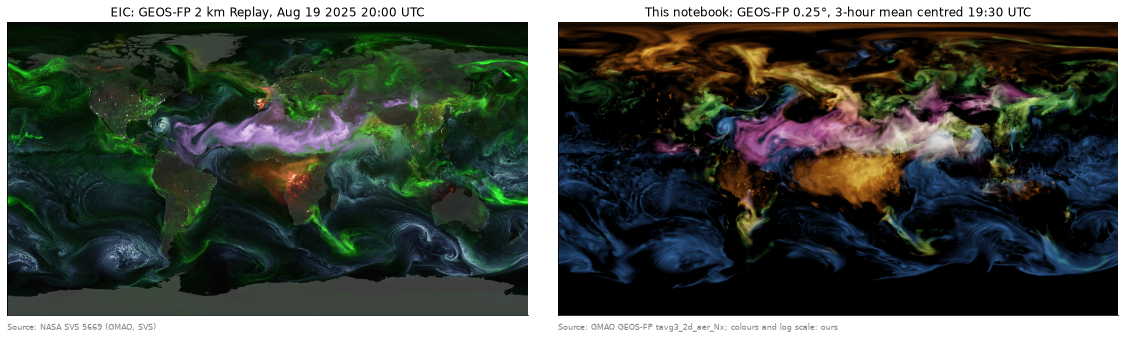

In [6]:
AOD_LO, AOD_HI = 0.03, 1.0


def level(aod):
    return np.clip(np.log10(np.maximum(aod, 1e-6) / AOD_LO) / np.log10(AOD_HI / AOD_LO), 0, 1)


def composite(aod4):
    """EIC-style colour picture of one frame (4, lat, lon), north up."""
    rgb = sum(level(aod4[i])[..., None] ** 1.3 * np.array(COLOR[s]) for i, s in enumerate(SPECIES))
    return (1 - np.exp(-1.6 * rgb))[::-1]


def show(ax, img, box=(-180, 180, -90, 90)):
    """Draw a composite cropped to box = (west, east, south, north)."""
    w, e, s, n = box
    i = (AOD_LON >= w) & (AOD_LON <= e)
    j = ((AOD_LAT >= s) & (AOD_LAT <= n))[::-1]
    ax.imshow(img[j][:, i], extent=box, aspect="auto")
    ax.set_facecolor("black")


svs_still = mpimg.imread(download("media/Aerosols_2025-08-19T20_00_00_1920x1080.png",
    "https://svs.gsfc.nasa.gov/vis/a000000/a005600/a005669/Aerosols_2025-08-19T20_00_00_1920x1080.png"))
still = composite(AOD[TIMES.get_loc(STILL)])

fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
axes[0].imshow(svs_still)
axes[0].set_title("EIC: GEOS-FP 2 km Replay, Aug 19 2025 20:00 UTC")
show(axes[1], still)
axes[1].set_title("This notebook: GEOS-FP 0.25°, 3-hour mean centred 19:30 UTC")
for ax in axes:
    ax.set_xticks([]), ax.set_yticks([])
source_note(axes[0], "Source: NASA SVS 5669 (GMAO, SVS)", -0.05)
source_note(axes[1], "Source: GMAO GEOS-FP tavg3_2d_aer_Nx; colours and log scale: ours", -0.05)
plt.tight_layout()

EIC's still is a globe seen from over the Atlantic; ours is the whole world, flat. The same features appear in both: Erin's blue spiral east of Florida, the pink dust band from the Sahara to the Caribbean, orange smoke over southern Africa and the South Atlantic, blue sea salt over the Southern Ocean.

How much of each type is in the air over the two weeks (area-weighted global mean AOD), and where each one peaks:

In [7]:
area = np.cos(np.radians(AOD_LAT))[:, None] * np.ones(len(AOD_LON))
global_mean = pd.DataFrame(
    {s: (AOD[:, i] * area).sum((1, 2)) / area.sum() for i, s in enumerate(SPECIES)}, index=TIMES)


def peak(i):
    mean = AOD[:, i].mean(0)
    j, k = np.unravel_index(mean.argmax(), mean.shape)
    return f"{AOD_LAT[j]:.0f}°, {AOD_LON[k]:.0f}°"


composition = pd.DataFrame({
    "global mean AOD": global_mean.mean(),
    "share of total (%)": global_mean.mean() / global_mean.mean().sum() * 100,
    "highest 2-week mean at (lat, lon)": [peak(i) for i in range(4)],
}, index=SPECIES).rename(index=SPECIES_NAME)
composition.round(3)

,global mean AOD,share of total (%),"highest 2-week mean at (lat, lon)"
sea salt,0.035,25.258,"18°, 73°"
dust,0.027,19.819,"38°, 80°"
smoke,0.046,33.299,"-4°, 18°"
sulfate,0.030,21.624,"40°, 116°"


## 5. Message 2: Hurricane Erin churns up sea salt and pulls in dust

[5669](https://svs.gsfc.nasa.gov/5669/), [NHC best track for Erin](https://ftp.nhc.noaa.gov/atcf/archive/2025/bal052025.dat.gz)

> "As the first Atlantic hurricane of the 2025 season, Erin is visible in the Atlantic Ocean pulling in dust from Africa. The storm's powerful winds churn up ocean water, creating sea salt particles visible as blue spirals."

Erin's position and strength every 6 hours come from the National Hurricane Center's best track. Erin formed as a tropical depression on Aug 11, 00 UTC, at 16.5° N, 23.1° W, just west of the Cape Verde Islands (a Cape Verde hurricane, born where the Saharan dust leaves Africa); it became a hurricane on Aug 15 at 18.0° N, 55.2° W and peaked at 140 kt on Aug 16 at 19.8° N, 63.4° W. The album's two weeks start 1.5 hours after it formed. Around the eye we compare the AOD of sea salt and dust within 500 km with a ring 1,000 to 2,000 km out.

,within 500 km,"1,000–2,000 km out",ratio
sea salt,0.202,0.033,6.178
dust,0.057,0.073,0.783
smoke,0.021,0.041,0.518
sulfate,0.032,0.035,0.901


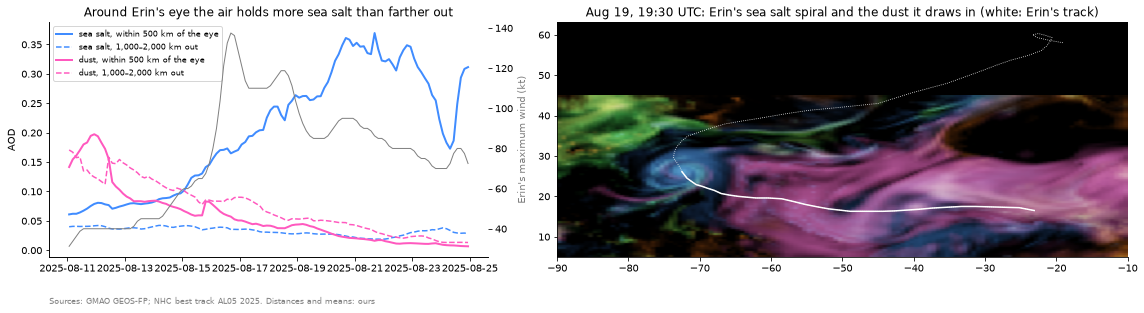

In [8]:
def best_track(path):
    rows = []
    for text in gzip.open(path, "rt"):
        line = [x.strip() for x in text.split(",")]
        if line[4] != "BEST":
            continue
        lat, lon = line[6].strip(), line[7].strip()
        rows.append({"time": pd.to_datetime(line[2].strip(), format="%Y%m%d%H"),
                     "lat": float(lat[:-1]) / 10 * (1 if lat[-1] == "N" else -1),
                     "lon": float(lon[:-1]) / 10 * (-1 if lon[-1] == "W" else 1),
                     "wind_kt": int(line[8]), "pressure_hpa": int(line[9]), "kind": line[10]})
    return pd.DataFrame(rows).drop_duplicates("time").set_index("time")


erin = best_track(download("bal052025.dat.gz", ERIN_URL))
erin_at = erin[["lat", "lon", "wind_kt"]].reindex(erin.index.union(TIMES)).interpolate("time").loc[TIMES]


def distance_km(lat0, lon0, lat, lon):
    """Great-circle distance from one point to grids of points."""
    p0, p, dl = np.radians(lat0), np.radians(lat), np.radians(lon - lon0)
    return 6371 * np.arccos(np.clip(np.sin(p0) * np.sin(p) + np.cos(p0) * np.cos(p) * np.cos(dl), -1, 1))


LAT2, LON2 = np.meshgrid(AOD_LAT, AOD_LON, indexing="ij")
near, ring = {}, {}
for n, (t, row) in enumerate(erin_at.iterrows()):
    d = distance_km(row.lat, row.lon, LAT2, LON2)
    for i, s in enumerate(SPECIES):
        near.setdefault(s, []).append(AOD[n, i][d < 500].mean())
        ring.setdefault(s, []).append(AOD[n, i][(d > 1000) & (d < 2000)].mean())
near, ring = pd.DataFrame(near, index=TIMES), pd.DataFrame(ring, index=TIMES)

fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1, 1.3]})
ax = axes[0]
for s in ("sea_salt", "dust"):
    ax.plot(near.index, near[s], color=COLOR[s], linewidth=2, label=f"{SPECIES_NAME[s]}, within 500 km of the eye")
    ax.plot(ring.index, ring[s], color=COLOR[s], linestyle="--", label=f"{SPECIES_NAME[s]}, 1,000–2,000 km out")
ax.set_ylabel("AOD")
wind = ax.twinx()
wind.plot(erin_at.index, erin_at["wind_kt"], color="gray", linewidth=1)
wind.set_ylabel("Erin's maximum wind (kt)", color="gray")
ax.legend(fontsize=8, loc="upper left")
ax.set_title("Around Erin's eye the air holds more sea salt than farther out")
source_note(ax, "Sources: GMAO GEOS-FP; NHC best track AL05 2025. Distances and means: ours", -0.2)

box = (-90, -10, 5, 45)
show(axes[1], still, box)
past = erin[erin.index <= STILL]
axes[1].plot(erin["lon"], erin["lat"], color="white", linewidth=0.8, linestyle=":")
axes[1].plot(past["lon"], past["lat"], color="white", linewidth=1.5)
axes[1].set_title("Aug 19, 19:30 UTC: Erin's sea salt spiral and the dust it draws in (white: Erin's track)")
plt.tight_layout()

erin_stats = pd.DataFrame({"within 500 km": near.mean(), "1,000–2,000 km out": ring.mean()})
erin_stats["ratio"] = erin_stats.iloc[:, 0] / erin_stats.iloc[:, 1]
erin_stats.rename(index=SPECIES_NAME).round(3)

- The table is the average over the two weeks. The ratio says how much more of each type sits near the eye than in the air around it.
- Sea salt near the eye follows the storm's wind: it grows with Erin's strength, as EIC says the winds "churn up ocean water".
- The map shows dust wrapping into the storm's western side from the band that crosses the Atlantic. The numbers alone cannot show "pulling in"; that is EIC's reading of the motion, and the flow export in section 10 lets the globe show it.

## 6. Message 3: Saharan dust crosses the Atlantic

[5669](https://svs.gsfc.nasa.gov/5669/)

> "Desert dust from the Sahara travels all the way across the Atlantic Ocean, creating hazy skies in the Caribbean and affecting air quality as it reaches the United States."

A time–longitude picture (Hovmöller diagram) of dust AOD averaged over 10 to 25° N shows the journey: each dust outbreak leaves Africa on the right and runs to the left, west, as a slanted stripe. The slope is its speed.

- Dust AOD over the Caribbean (10–25° N, 80–60° W): mean **0.09**, peak **0.19** on Aug 13.
- Off the African coast (25–15° W) the mean is **0.28**.
- The outbreak that leaves the African coast (20° W) on Aug 14 peaks at 70° W on Aug 21: 5,317 km in **6.8 days**, about **10 m/s** (ours: a line fitted to the time of its peak at every 5° of longitude).
- The Caribbean's first peak, on Aug 13, belongs to an earlier outbreak that left Africa before these two weeks.

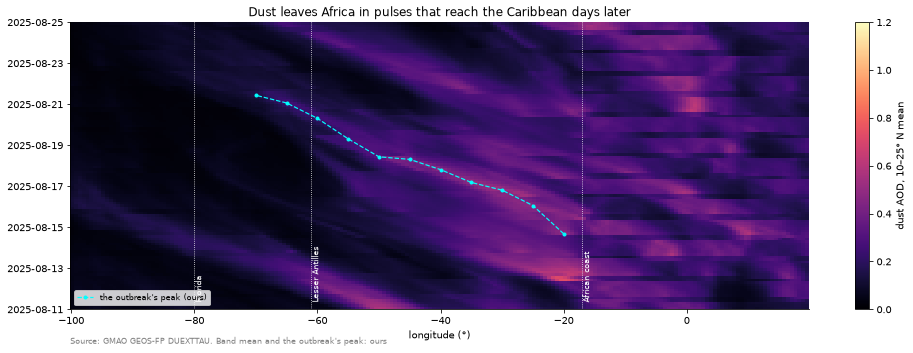

In [9]:
def band(i, south, north, west=-180, east=180):
    j = (AOD_LAT >= south) & (AOD_LAT <= north)
    k = (AOD_LON >= west) & (AOD_LON <= east)
    w = np.cos(np.radians(AOD_LAT[j]))
    return (AOD[:, i][:, j][:, :, k] * w[None, :, None]).sum(1) / w.sum(), AOD_LON[k]


DUST = SPECIES.index("dust")
hov, hov_lon = band(DUST, 10, 25, -100, 20)
fig, ax = plt.subplots(figsize=(14, 5))
im = ax.pcolormesh(hov_lon, TIMES, hov, cmap="magma", vmin=0, vmax=1.2, shading="auto")
for x, name in [(-17, "African coast"), (-61, "Lesser Antilles"), (-80, "Florida")]:
    ax.axvline(x, color="white", linewidth=0.8, linestyle=":")
    ax.text(x, TIMES[1], f" {name}", color="white", fontsize=8, rotation=90, va="bottom")
fig.colorbar(im, label="dust AOD, 10–25° N mean")
ax.set_xlabel("longitude (°)")
ax.set_title("Dust leaves Africa in pulses that reach the Caribbean days later")
# Follow the outbreak that leaves the coast in these weeks: the time its dust peaks at every 5° of longitude.
follow_lon = np.arange(-20.0, -71.0, -5.0)
window = (TIMES >= "2025-08-14") & (TIMES < "2025-08-23")
peak_at = TIMES[window][hov[window][:, [np.abs(hov_lon - x).argmin() for x in follow_lon]].argmax(0)]
ax.plot(follow_lon, peak_at, color="cyan", linewidth=1.2, linestyle="--", marker="o", markersize=3, label="the outbreak's peak (ours)")
ax.legend(loc="lower left", fontsize=8)
source_note(ax, "Source: GMAO GEOS-FP DUEXTTAU. Band mean and the outbreak's peak: ours")
plt.tight_layout()

caribbean = pd.Series(band(DUST, 10, 25, -80, -60)[0].mean(1), index=TIMES)
african_coast = pd.Series(band(DUST, 10, 25, -25, -15)[0].mean(1), index=TIMES)
hours = (peak_at - peak_at[0]).total_seconds() / 3600
along_km = (follow_lon[0] - follow_lon) * 111.2 * np.cos(np.radians(17))  # westward from 20° W, along 17° N
speed_m_s = np.polyfit(hours, along_km, 1)[0] / 3.6
crossing_km, crossing_days = along_km[-1], hours[-1] / 24
display(Markdown(f"- Dust AOD over the Caribbean (10–25° N, 80–60° W): mean **{caribbean.mean():.2f}**, peak **{caribbean.max():.2f}** on {caribbean.idxmax():%b %d}.\n"
                 f"- Off the African coast (25–15° W) the mean is **{african_coast.mean():.2f}**.\n"
                 f"- The outbreak that leaves the African coast (20° W) on {peak_at[0]:%b %d} peaks at 70° W on {peak_at[-1]:%b %d}: "
                 f"{crossing_km:,.0f} km in **{crossing_days:.1f} days**, about **{speed_m_s:.0f} m/s** (ours: a line fitted to the time of its peak at every 5° of longitude).\n"
                 f"- The Caribbean's first peak, on {caribbean.idxmax():%b %d}, belongs to an earlier outbreak that left Africa before these two weeks."))


## 7. Message 4: smoke from southern Africa and from Spain

[5669](https://svs.gsfc.nasa.gov/5669/)

> "In southern Africa, seasonal agricultural burning created smoke that drifted over the Atlantic Ocean" and "Wildfires raged across multiple regions in Spain".

Smoke AOD over three boxes: the burning region of southern Africa, the Atlantic off its coast, and Spain.

,mean,max,idxmax
"southern Africa, land (20–5° S, 12–35° E)",0.371053,0.50074,2025-08-24 22:30:00
"Atlantic off Angola and Namibia (20–5° S, 10° W–10° E)",0.241002,0.390259,2025-08-24 10:30:00
"Spain (36–44° N, 10° W–3° E)",0.204073,0.497491,2025-08-18 16:30:00


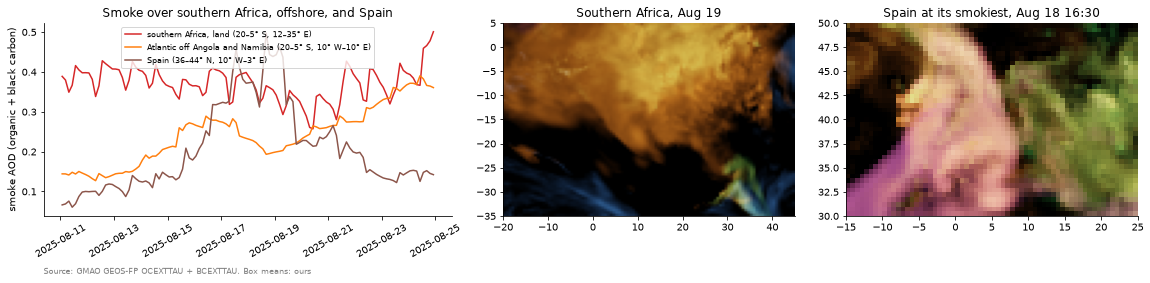

In [10]:
SMOKE = SPECIES.index("smoke")
smoke_boxes = {
    "southern Africa, land (20–5° S, 12–35° E)": (-20, -5, 12, 35),
    "Atlantic off Angola and Namibia (20–5° S, 10° W–10° E)": (-20, -5, -10, 10),
    "Spain (36–44° N, 10° W–3° E)": (36, 44, -10, 3),
}
smoke = pd.DataFrame({k: band(SMOKE, s, n, w, e)[0].mean(1) for k, (s, n, w, e) in smoke_boxes.items()}, index=TIMES)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.4, 1, 1]})
for (name, series), color in zip(smoke.items(), ["tab:red", "tab:orange", "tab:brown"]):
    axes[0].plot(series.index, series.values, label=name, color=color)
axes[0].set_ylabel("smoke AOD (organic + black carbon)")
axes[0].legend(fontsize=8)
axes[0].tick_params(axis="x", labelrotation=30)
axes[0].set_title("Smoke over southern Africa, offshore, and Spain")
source_note(axes[0], "Source: GMAO GEOS-FP OCEXTTAU + BCEXTTAU. Box means: ours", -0.3)
show(axes[1], still, (-20, 45, -35, 5))
axes[1].set_title("Southern Africa, Aug 19")
spain_peak = smoke.iloc[:, 2].idxmax()
show(axes[2], composite(AOD[TIMES.get_loc(spain_peak)]), (-15, 25, 30, 50))
axes[2].set_title(f"Spain at its smokiest, {spain_peak:%b %d %H:%M}")
plt.tight_layout()
smoke.agg(["mean", "max", "idxmax"]).T

- Southern Africa's smoke is the thickest of all four types anywhere in these weeks (see section 4), and the offshore box shows a large part of it over the ocean, as EIC says.
- Spain's smoke comes in short bursts; we read its peak from the data, EIC only says the fires "raged".

## 8. Message 5: volcanoes send out narrow streams of sulfate

[5669](https://svs.gsfc.nasa.gov/5669/)

> "Hawaii's Kilauea Volcano released a narrow stream of sulfate particles moving westward, while Italy's Mount Etna created similar streams over southern Europe."

Sulfate also comes from pollution, so the check looks where there is little of it: the open Pacific west of Kilauea (19.4° N, 155.3° W). A time–longitude picture along 17 to 22° N shows whether the stream runs west.

- Sulfate AOD west of Kilauea (175–157° W): mean **0.017**; east of it (153–135° W): **0.018**, so downwind holds **0.9×** as much as upwind.

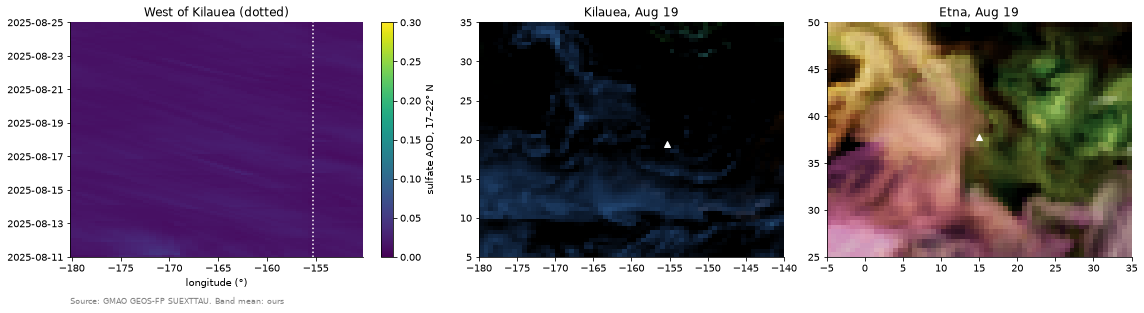

In [11]:
SULF = SPECIES.index("sulfate")
KILAUEA, ETNA = (19.4, -155.3), (37.75, 15.0)
hov, hov_lon = band(SULF, 17, 22, -180, -150)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), gridspec_kw={"width_ratios": [1.2, 1, 1]})
im = axes[0].pcolormesh(hov_lon, TIMES, hov, cmap="viridis", vmin=0, vmax=0.3, shading="auto")
axes[0].axvline(KILAUEA[1], color="white", linestyle=":")
fig.colorbar(im, ax=axes[0], label="sulfate AOD, 17–22° N")
axes[0].set_xlabel("longitude (°)")
axes[0].set_title("West of Kilauea (dotted)")
source_note(axes[0], "Source: GMAO GEOS-FP SUEXTTAU. Band mean: ours", -0.2)
show(axes[1], still, (-180, -140, 5, 35))
axes[1].plot(KILAUEA[1], KILAUEA[0], "w^")
axes[1].set_title("Kilauea, Aug 19")
show(axes[2], still, (-5, 35, 25, 50))
axes[2].plot(ETNA[1], ETNA[0], "w^")
axes[2].set_title("Etna, Aug 19")
plt.tight_layout()

west = band(SULF, 17, 22, -175, -157)[0].mean(1)
east = band(SULF, 17, 22, -153, -135)[0].mean(1)
display(Markdown(f"- Sulfate AOD west of Kilauea (175–157° W): mean **{west.mean():.3f}**; east of it (153–135° W): **{east.mean():.3f}**, "
                 f"so downwind holds **{west.mean() / east.mean():.1f}×** as much as upwind."))

- GEOS-FP holds **no stream west of Kilauea** in these weeks: the air downwind carries no more sulfate than the air upwind, and both sit near the clean-air floor. The model's emissions do not include Kilauea's eruption episodes of August 2025 at this resolution, so the data cannot show what EIC's image shows here.
- The album therefore has **no Kilauea track**. Etna's stream is in the data (section 9.4), so the volcanic part of the message is played by Etna in the Spain and Etna track.

## 9. Message summary and track candidates

### 9.1 Message summary

In [12]:
summary = pd.DataFrame([
    ["Four kinds of particles", f"Global mean AOD: sea salt {composition.iloc[0, 0]:.3f}, dust {composition.iloc[1, 0]:.3f}, smoke {composition.iloc[2, 0]:.3f}, sulfate {composition.iloc[3, 0]:.3f}", "all tracks, four stems"],
    ["Erin churns up sea salt", f"Sea salt within 500 km of the eye is {erin_stats.loc['sea_salt', 'ratio']:.1f}× the air 1,000–2,000 km out", "Erin"],
    ["Saharan dust crosses the Atlantic", f"Caribbean dust AOD peaks at {caribbean.max():.2f}; an outbreak crosses from 20° W to 70° W in {crossing_days:.1f} days, about {speed_m_s:.0f} m/s", "Saharan Dust"],
    ["Smoke from southern Africa and Spain", f"Southern Africa smoke AOD mean {smoke.iloc[:, 0].mean():.2f}, offshore {smoke.iloc[:, 1].mean():.2f}; Spain peaks at {smoke.iloc[:, 2].max():.2f}", "Southern Africa Smoke, Spain and Etna"],
    ["Volcanic sulfate streams", f"Sulfate west of Kilauea is {west.mean() / east.mean():.1f}× that east of it", "Spain and Etna (Kilauea: no stream in GEOS-FP)"],
], columns=["message (EIC, 5669)", "key number (ours, from GEOS-FP)", "track"])
summary

,"message (EIC, 5669)","key number (ours, from GEOS-FP)",track
0,Four kinds of particles,"Global mean AOD: sea salt 0.035, dust 0.027, smoke 0.046, sulfate 0.030","all tracks, four stems"
1,Erin churns up sea salt,"Sea salt within 500 km of the eye is 6.2× the air 1,000–2,000 km out",Erin
2,Saharan dust crosses the Atlantic,"Caribbean dust AOD peaks at 0.19; an outbreak crosses from 20° W to 70° W in 6.8 days, about 10 m/s",Saharan Dust
3,Smoke from southern Africa and Spain,"Southern Africa smoke AOD mean 0.37, offshore 0.24; Spain peaks at 0.50","Southern Africa Smoke, Spain and Etna"
4,Volcanic sulfate streams,Sulfate west of Kilauea is 0.9× that east of it,Spain and Etna (Kilauea: no stream in GEOS-FP)


### 9.2 Tracks: one view each, four stems each

EIC's still is one moment; the album plays the two weeks around it, three hours a step. Each track **looks at one place** (the globe turns to it, and for Erin it follows the eye), and its **four stems are the four particle types seen from there**. A stem is louder when more of its colour is on screen, so the mix changes as the view and the air change. This is the multi-track the challenge asks for: muting a colour on the globe mutes its stem.

What each stem reads, in every frame (ours):

- **amount**: the mean AOD of the type over the visible half of the globe, weighted towards the centre of the view (weight cos⁴ of the angle from the centre, so half the weight lies within about 33°).
- **north, east**: where that type sits in the view, as the AOD-weighted centre in degrees north and east of the view's centre.
- **speed**: how fast that type is moving there, total mass flux over total mass, in m/s.

| Track | View | Lead stem | EIC message |
| --- | --- | --- | --- |
| Erin | follows the eye | sea salt, with dust | Hurricane Erin |
| Saharan Dust | 17° N, 45° W, mid-Atlantic | dust | Saharan dust journey |
| Southern Africa Smoke | 12° S, 5° E, the coast of Angola | smoke | Wildfire smoke |
| Spain and Etna | 40° N, 5° E, the western Mediterranean | smoke and sulfate | Wildfire smoke, volcanic plumes |

Kilauea is left out: GEOS-FP has no stream there (section 8).

,sea salt,dust,smoke,sulfate
Erin,0.029 (0.025–0.033),0.058 (0.040–0.094),0.060 (0.042–0.098),0.032 (0.028–0.038)
Saharan Dust,0.031 (0.025–0.039),0.072 (0.050–0.082),0.066 (0.054–0.084),0.030 (0.028–0.032)
Southern Africa Smoke,0.025 (0.022–0.029),0.044 (0.034–0.051),0.136 (0.107–0.191),0.033 (0.027–0.036)
Spain and Etna,0.015 (0.013–0.021),0.090 (0.066–0.109),0.106 (0.093–0.117),0.051 (0.043–0.057)


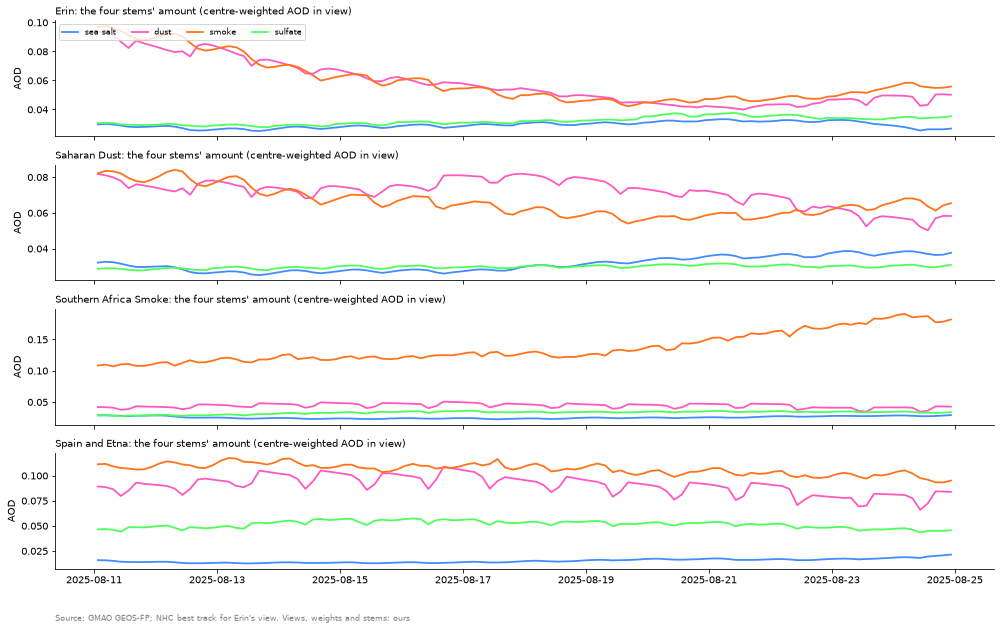

In [13]:
VIEWS = {
    "erin": ("Erin", None),
    "saharan_dust": ("Saharan Dust", (17.0, -45.0)),
    "southern_africa_smoke": ("Southern Africa Smoke", (-12.0, 5.0)),
    "spain_and_etna": ("Spain and Etna", (40.0, 5.0)),
}
FLAT2, FLON2 = np.meshgrid(FLOW_LAT, FLOW_LON, indexing="ij")


def view_frame(lat0, lon0, lat, lon):
    """Weights and local east/north coordinates (degrees) of grid points seen from a view centre."""
    p0, p, dl = np.radians(lat0), np.radians(lat), np.radians(lon - lon0)
    cos_d = np.sin(p0) * np.sin(p) + np.cos(p0) * np.cos(p) * np.cos(dl)
    w = np.clip(cos_d, 0, None) ** 4 * np.cos(p)  # visible half, centre-weighted, per unit area
    east = np.cos(p) * np.sin(dl)
    north = np.cos(p0) * np.sin(p) - np.sin(p0) * np.cos(p) * np.cos(dl)
    return w, np.degrees(np.arcsin(np.clip(east, -1, 1))), np.degrees(np.arcsin(np.clip(north, -1, 1)))


def stems(track):
    centre = erin_at[["lat", "lon"]] if VIEWS[track][1] is None else pd.DataFrame(
        [VIEWS[track][1]] * len(TIMES), index=TIMES, columns=["lat", "lon"])
    rows = []
    for n, t in enumerate(TIMES):
        lat0, lon0 = centre.loc[t]
        w, east, north = view_frame(lat0, lon0, LAT2, LON2)
        fw, *_ = view_frame(lat0, lon0, FLAT2, FLON2)
        row = {"time": t.strftime("%Y-%m-%dT%H:%MZ"), "view_lat": round(lat0, 2), "view_lon": round(lon0, 2)}
        for i, s in enumerate(SPECIES):
            a = AOD[n, i] * w
            row[f"{s}_aod"] = a.sum() / w.sum()
            row[f"{s}_north_deg"] = (a * north).sum() / a.sum()
            row[f"{s}_east_deg"] = (a * east).sum() / a.sum()
            row[f"{s}_speed_m_s"] = (fw * np.hypot(FU[n, i], FV[n, i])).sum() / (fw * MASS[n, i]).sum()
        rows.append(row)
    out = pd.DataFrame(rows)
    if track == "erin":
        out["erin_wind_kt"] = erin_at["wind_kt"].round().astype(int).values
    return out


track_data = {k: stems(k) for k in VIEWS}

fig, axes = plt.subplots(len(VIEWS), 1, figsize=(14, 2.2 * len(VIEWS)), sharex=True)
for ax, (k, df) in zip(axes, track_data.items()):
    for s in SPECIES:
        ax.plot(TIMES, df[f"{s}_aod"], color=COLOR[s], linewidth=1.8, label=SPECIES_NAME[s])
    ax.set_title(f"{VIEWS[k][0]}: the four stems' amount (centre-weighted AOD in view)", fontsize=10, loc="left")
    ax.set_ylabel("AOD")
axes[0].legend(fontsize=8, ncol=4, loc="upper left")
source_note(axes[-1], "Source: GMAO GEOS-FP; NHC best track for Erin's view. Views, weights and stems: ours", -0.45)
plt.tight_layout()

pd.DataFrame({VIEWS[k][0]: {SPECIES_NAME[s]: f"{df[f'{s}_aod'].mean():.3f} ({df[f'{s}_aod'].min():.3f}–{df[f'{s}_aod'].max():.3f})"
                            for s in SPECIES} for k, df in track_data.items()}).T

The table gives each stem's mean amount and its range over the two weeks. A good track has one stem that leads and changes over time while the others stay behind it: that is the stem the listener follows.

### 9.3 How the stems could sound (ours, for the `music` feature)

Each stem keeps one meaning across all tracks, so what a listener learns on one track holds on the next. The four are told apart by timbre and register, from the sea up to the volcanoes:

| Stem | Texture | Register | Amount → | North, east → | Speed → |
| --- | --- | --- | --- | --- | --- |
| sea salt (blue) | surf: swelling filtered noise under low strings | lowest | loudness | pitch, pan | how fast the swells come |
| smoke (orange) | crackle grains over a warm cello or bassoon drone | low middle | loudness, crackle density | pitch, pan | grain rate |
| dust (pink) | dry sand grains, shaker or cabasa | high middle | grain density | pitch, pan | grain rate |
| sulfate (green) | a thin glassy held tone, glass harmonica | highest | loudness | pitch, pan | slow vibrato |

The view centre is the middle of the stereo field and the pitch of the scale's tonic, so a plume drifting west of the view moves to the left, and one to the north sounds higher. In Erin's track the storm's wind (`erin_wind_kt`) can add the one accent, a timpani stroke at its peak, as the glacier album does for a record low.

### 9.4 How far each event reaches (ours)

EIC's message for the whole image is the link between places: "This visualization still image highlights how our atmosphere connects distant parts of the world. What happens in one region—whether natural events or human activities—can affect weather patterns and air quality thousands of miles away." The stems of 9.2 hear what is in view; this section measures, for each track, **an event leaving its source and reaching a distant place**. Erin's own event is the one EIC names first, the sea salt its winds churn up at the eye; it is measured where it starts and how far it spreads, and the dust it pulls in from Africa is a second, smaller event:

| Track | Event (source) | Distant place (receptor) | Particle |
| --- | --- | --- | --- |
| Erin (lead) | Erin's eye, from the NHC best track | (none: the storm's own salt) | sea salt |
| Erin | the Sahara, 18° N, 2° E | Erin's eye | dust |
| Saharan Dust | the Sahara | the Caribbean, 17.5° N, 67.5° W | dust |
| Southern Africa Smoke | the fires of southern Africa, 12° S, 22° E | St Helena, 15.9° S, 5.7° W | smoke |
| Spain and Etna | the fires of northwest Spain, 42° N, 6° W | Britain, 52.5° N, 1.5° W | smoke |
| Spain and Etna | Etna, 37.75° N, 15.0° E | Greece, 38.5° N, 22.5° E | sulfate |

The receptors are ours. EIC names the Caribbean and the United States for the dust and the Atlantic for the smoke; Britain and Greece are where the maps of section 7 and 8 show Spain's smoke and Etna's sulfate heading.

In every frame:

- **the plume** is the air with more than a threshold AOD (sea salt 0.15, dust and smoke 0.2, sulfate 0.12) that is connected, cell to cell, to the source. Air above the threshold that is not connected to the source belongs to some other event and is left out.
- **source**: mean AOD within a few hundred km of the source (600 km for the Sahara and southern Africa, 300 km for Erin's eye and Spain, 150 km for Etna): how strong the event is.
- **reach**: the 95th percentile of the plume's distance from the source, in km: how far it has spread in any direction.
- **area**: the plume's area, in million km².
- **front**: the plume's point nearest the receptor, and its distance to it: how close the event has come.
- **receptor**: mean AOD within 400 to 800 km of the receptor (500 km around Erin's eye): what arrives there.


- **Erin**, sea salt at Erin's eye: the AOD there goes from 0.06 to **0.56**; the plume first covers 0.1 million km² on Aug 14 and reaches **0 to 1,927 km**, covering up to **1.1 million km²**.
- **Erin**, dust from the Sahara: reaches **997 to 6,860 km**, covering up to **19.6 million km²**; its front comes within **142 km** of Erin's eye on Aug 11, and the AOD there goes from 0.01 to **0.20** (peak Aug 11).
- **Saharan Dust**, dust from the Sahara: reaches **997 to 6,860 km**, covering up to **19.6 million km²**; its front comes within **353 km** of the Caribbean on Aug 20, and the AOD there goes from 0.03 to **0.25** (peak Aug 13).
- **Southern Africa Smoke**, smoke from southern Africa's fires: reaches **2,518 to 5,509 km**, covering up to **18.0 million km²**; its front comes within **27 km** of St Helena on Aug 23, and the AOD there goes from 0.02 to **0.17** (peak Aug 24).
- **Spain and Etna**, smoke from Spain's fires: reaches **197 to 4,162 km**, covering up to **4.7 million km²**; its front comes within **15 km** of Britain on Aug 15, and the AOD there goes from 0.05 to **0.27** (peak Aug 18).
- **Spain and Etna**, sulfate from Etna: reaches **0 to 1,185 km**, covering up to **0.9 million km²**; its front comes within **14 km** of Greece on Aug 14, and the AOD there goes from 0.03 to **0.14** (peak Aug 18).

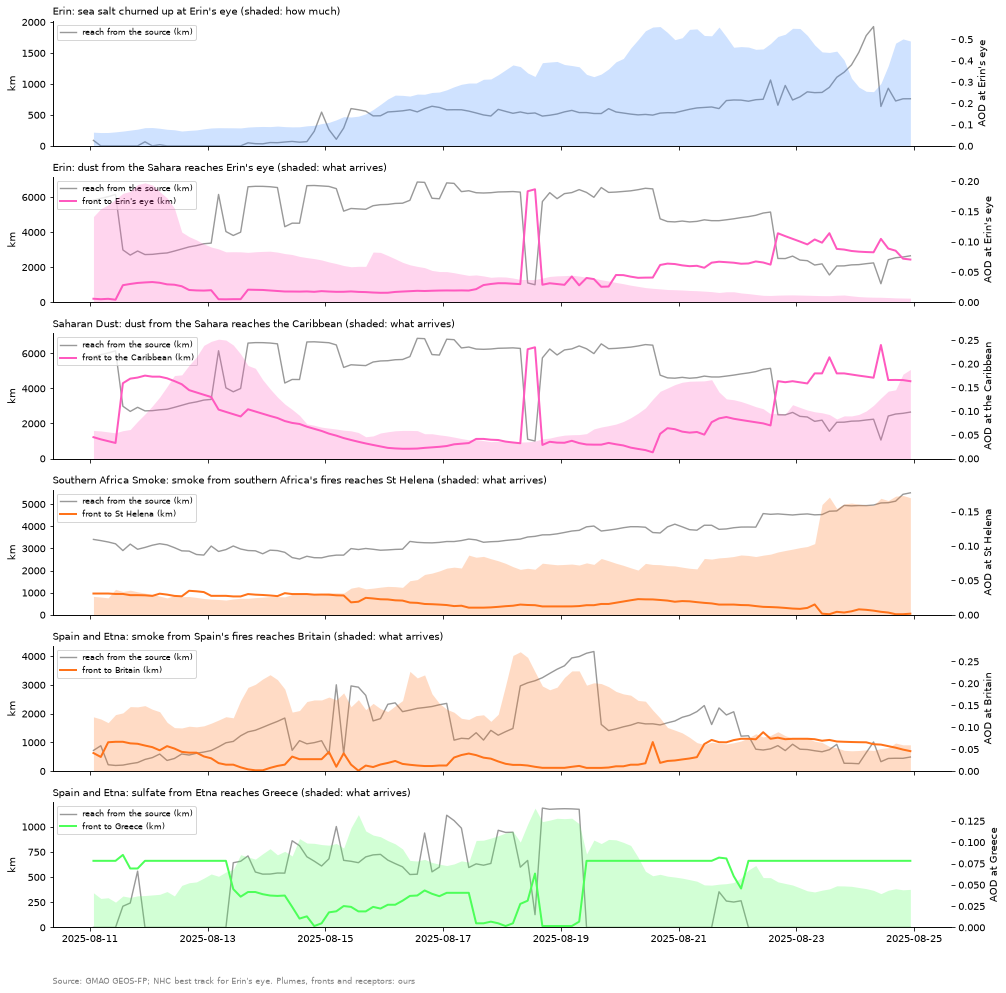

In [14]:
from scipy import ndimage

SAHARA, SOUTHERN_AFRICA, SPAIN = (18.0, 2.0), (-12.0, 22.0), (42.0, -6.0)
CARIBBEAN, ST_HELENA, BRITAIN, GREECE = (17.5, -67.5), (-15.9, -5.7), (52.5, -1.5), (38.5, 22.5)
EYE = "eye"  # Erin's eye, from the NHC best track, wherever it is in the frame
THRESHOLD = {"sea_salt": 0.15, "dust": 0.2, "smoke": 0.2, "sulfate": 0.12}
# Each track's events, the lead first: particle, source name, source, source radius (km), receptor name, receptor, its
# radius. An event with no receptor (None) is measured where it starts and how far it spreads only.
PLUMES = {
    "erin": [("sea_salt", "Erin's eye", EYE, 300, None, None, 0),
             ("dust", "the Sahara", SAHARA, 600, "Erin's eye", EYE, 500)],
    "saharan_dust": [("dust", "the Sahara", SAHARA, 600, "the Caribbean", CARIBBEAN, 800)],
    "southern_africa_smoke": [("smoke", "southern Africa's fires", SOUTHERN_AFRICA, 600, "St Helena", ST_HELENA, 600)],
    "spain_and_etna": [("smoke", "Spain's fires", SPAIN, 300, "Britain", BRITAIN, 500),
                       ("sulfate", "Etna", ETNA, 150, "Greece", GREECE, 400)],
}
CELL_KM2 = np.cos(np.radians(LAT2)) * np.radians(0.5) * np.radians(AOD_LON[1] - AOD_LON[0]) * 6371.0**2


def plume(n, species, source, source_km, receptor, receptor_km):
    """The connected plume of one particle type from its source in frame n, and how near it comes to the receptor."""
    a = AOD[n, SPECIES.index(species)]
    from_source = distance_km(*source, LAT2, LON2)
    at_source = from_source < source_km
    labels, _ = ndimage.label(a > THRESHOLD[species])
    ids = np.unique(labels[at_source])
    body = np.isin(labels, ids[ids > 0])
    row = {"source_aod": a[at_source].mean(),
           "reach_km": np.percentile(from_source[body], 95) if body.any() else 0.0,
           "area_million_km2": CELL_KM2[body].sum() / 1e6}
    if receptor is None:
        return row
    to_receptor = distance_km(*receptor, LAT2, LON2)
    row["receptor_aod"] = a[to_receptor < receptor_km].mean()
    if not body.any():
        return row | {"front_lat": source[0], "front_lon": source[1], "front_to_receptor_km": float(distance_km(*source, *receptor))}
    j, k = np.unravel_index(np.where(body, to_receptor, np.inf).argmin(), a.shape)
    return row | {"front_lat": AOD_LAT[j], "front_lon": AOD_LON[k], "front_to_receptor_km": to_receptor[j, k]}


def reach(track):
    out = []
    for n, t in enumerate(TIMES):
        eye = tuple(erin_at.loc[t, ["lat", "lon"]])
        place = lambda p: eye if p == EYE else p
        row = {}
        for species, _, source, source_km, _, receptor, receptor_km in PLUMES[track]:
            measured = plume(n, species, place(source), source_km, place(receptor), receptor_km)
            row |= {f"{species}_{k}": v for k, v in measured.items()}
        out.append(row)
    return pd.DataFrame(out)


reach_data = {k: reach(k) for k in PLUMES}
for k in PLUMES:
    track_data[k] = pd.concat([track_data[k].drop(columns=reach_data[k].columns, errors="ignore"), reach_data[k]], axis=1)

events = [(k, p) for k in PLUMES for p in PLUMES[k]]
fig, axes = plt.subplots(len(events), 1, figsize=(14, 2.3 * len(events)), sharex=True)
for ax, (k, (species, source_name, _, _, receptor_name, _, _)) in zip(axes, events):
    df = reach_data[k]
    ax.plot(TIMES, df[f"{species}_reach_km"], color="0.6", linewidth=1.4, label="reach from the source (km)")
    ax.set_ylabel("km")
    ax.set_ylim(0, None)
    right = ax.twinx()
    if receptor_name is None:
        right.fill_between(TIMES, df[f"{species}_source_aod"], color=COLOR[species], alpha=0.25, linewidth=0)
        right.set_ylabel(f"AOD at {source_name}")
        title = f"{VIEWS[k][0]}: {SPECIES_NAME[species]} churned up at {source_name} (shaded: how much)"
    else:
        ax.plot(TIMES, df[f"{species}_front_to_receptor_km"], color=COLOR[species], linewidth=2, label=f"front to {receptor_name} (km)")
        right.fill_between(TIMES, df[f"{species}_receptor_aod"], color=COLOR[species], alpha=0.25, linewidth=0)
        right.set_ylabel(f"AOD at {receptor_name}")
        title = f"{VIEWS[k][0]}: {SPECIES_NAME[species]} from {source_name} reaches {receptor_name} (shaded: what arrives)"
    right.set_ylim(0, None)
    ax.set_title(title, fontsize=10, loc="left")
    ax.legend(fontsize=8, loc="upper left")
source_note(axes[-1], "Source: GMAO GEOS-FP; NHC best track for Erin's eye. Plumes, fronts and receptors: ours", -0.45)
plt.tight_layout()

lines = []
for k, (species, source_name, _, _, receptor_name, _, _) in events:
    df = reach_data[k].set_index(TIMES)
    spread = (f"reaches **{df[f'{species}_reach_km'].min():,.0f} to {df[f'{species}_reach_km'].max():,.0f} km**, "
              f"covering up to **{df[f'{species}_area_million_km2'].max():.1f} million km²**")
    if receptor_name is None:
        at = df[f"{species}_source_aod"]
        first = df.index[df[f"{species}_area_million_km2"] > 0.1][0]
        lines.append(f"- **{VIEWS[k][0]}**, {SPECIES_NAME[species]} at {source_name}: the AOD there goes from {at.min():.2f} to "
                     f"**{at.max():.2f}**; the plume first covers 0.1 million km² on {first:%b %d} and {spread}.")
        continue
    near = df[f"{species}_front_to_receptor_km"]
    arrive = df[f"{species}_receptor_aod"]
    lines.append(f"- **{VIEWS[k][0]}**, {SPECIES_NAME[species]} from {source_name}: {spread}; its front comes within "
                 f"**{near.min():,.0f} km** of {receptor_name} on {near.idxmin():%b %d}, and the AOD there "
                 f"goes from {arrive.min():.2f} to **{arrive.max():.2f}** (peak {arrive.idxmax():%b %d}).")
display(Markdown("\n".join(lines)))


- Every event is small where it starts, a few hundred km of thick air, and is measured thousands of km away within days: this is EIC's "thousands of miles away" in the data.
- Erin's sea salt has no plume while it is a tropical storm; once its winds pass about 60 kt (Aug 15) a plume of salt forms round the eye and grows to about a million km², as EIC's \"blue spirals\". Erin is born inside the Saharan dust and leaves it, the dust's front falling behind the eye as the storm grows (section 5).
- The Caribbean sees two dust outbreaks. The first (peak Aug 13) left Africa before these two weeks and has broken off from the source, so no connected front leads to it: it is heard only as what arrives. The second is followed the whole way: its front closes from about 4,600 km to 350 km between Aug 12 and Aug 20, and the Caribbean's dust rises again on Aug 19 to 21.
- Etna's stream exists from Aug 13 to 19; outside it the front sits at the volcano. Spain's smoke reaches Britain twice, around Aug 15 and Aug 18.
- The reach jumps when the plume joins or loses another patch of thick air of the same type, and for a step when the air at the source drops below the threshold (Aug 18). The front and the receptor are steadier, so the music should lean on them and smooth the reach.

### 9.5 How the reach could sound (ours, for the `music` feature)

The same melody heard in two places tells the listener that the two places share something. So each event is one short **motif**:

The listener stands where the event starts, facing north, and every note is placed around them in space (an HRTF panner, as the bird album places its flock: east to the right, further away the quieter).

1. **Source**: the motif played right in front of the listener by one instrument; louder as the source AOD grows.
2. **Journey**: the motif's echoes, more of them as the plume's area grows, each sounding further out towards the plume's front than the last, spaced wider as the reach grows. How fast the particles move in view (mass flux over mass) sets how many notes an echo runs, split at the track's quartiles as the bird album splits its flock's speed; the run climbs on days the front closes on the receptor and falls on days it draws back. A plume with no receptor (Erin's salt) sends its echoes round the listener anticlockwise, as an Atlantic storm turns, faster as the wind rises.
3. **Arrival**: as the receptor's AOD rises, the motif comes back on a second instrument from the receptor's direction, far away: the far place now hears the event.

Each particle type keeps its two instruments across the album, and each event its motif, so what a listener learns on one track holds on the next:

| Particle | At the source | Where it arrives | Events (motif) |
| --- | --- | --- | --- |
| dust | nylon guitar | harp | the Sahara: Erin, Saharan Dust |
| smoke | cello | French horn | southern Africa's fires; Spain's fires |
| sulfate | celesta | vibraphone | Etna |
| sea salt | violin, under a string chord that gains a third once Erin is a hurricane (64 kt); timpani on its windiest day | | Erin's eye (lead) |

A bar is a day (8 steps, 3.2 s), and each bar takes the day's mean of every number, which smooths the reach's jumps. Loudness, the number of echoes, their spacing and the arrival are scaled between each track's smallest and largest day. Erin leads with its own motif, the sea salt at the eye, played in the middle and echoed round it as the salt spreads; the Sahara's motif is heard softly on the right, and arrives at the eye on the harp while the storm is still inside the dust. Saharan Dust then plays the Sahara's motif as its lead, now reaching the Caribbean.


## 10. Export

Writes the album's data to `data/aerosol/tracks/` ([data-guide.md](../docs/data-guide.md)):

- **one CSV per track**, one row per 3-hour step: the view centre and, for each particle type, its amount, position and speed; and, for the track's events, the plume's source AOD, reach, area, front and receptor AOD (section 9.4). The time column is ISO date and time in UTC (`2025-08-11T01:30Z`), since a track steps every three hours, not every day.
- **one picture per step for the globe**, shared by all tracks, in `frames/`: a PNG twice as tall as wide (576 × 722, 0.625° × 0.5°, north up, west edge at 180° W).
  - top half, RGB = dust, sulfate, sea salt AOD; bottom half, R = smoke AOD. Each as `255 × clip(log10(AOD / 0.01) / log10(300), 0, 1)`, so 0 is AOD 0.01 and 255 is AOD 3.
  - bottom half, G and B = eastward and northward speed of all the particles together (total flux over total mass), as `255 × (v + 40) / 80` m/s, for drawing the flow.
  - Plain RGB, no alpha channel: browsers premultiply alpha, which would wipe the data under a transparent pixel.
- `tracks.json` with the message, sources and credit of every track, and the frame encoding.

Files from an earlier export that no track uses any more are removed.

In [15]:
ENC_AOD_LO, ENC_AOD_HI, ENC_SPEED = 0.01, 3.0, 40.0


def encode_aod(a):
    return np.round(255 * np.clip(np.log10(np.maximum(a, 1e-6) / ENC_AOD_LO) / np.log10(ENC_AOD_HI / ENC_AOD_LO), 0, 1)).astype(np.uint8)


def encode_speed(v):
    return np.round(255 * np.clip((v + ENC_SPEED) / (2 * ENC_SPEED), 0, 1)).astype(np.uint8)


def frame_png(n):
    a = AOD[n]
    mass = np.maximum(MASS[n].sum(0), 1e-12)
    u, v = (np.kron(F[n].sum(0) / mass, np.ones((2, 2)))[:361, :576] for F in (FU, FV))  # 1° flow up to the AOD grid
    top = np.stack([encode_aod(a[SPECIES.index(s)]) for s in ("dust", "sulfate", "sea_salt")], -1)
    bottom = np.stack([encode_aod(a[SMOKE]), encode_speed(u), encode_speed(v)], -1)
    return np.concatenate([top[::-1], bottom[::-1]])  # each half north up


def downloaded(paths):
    return date.fromtimestamp(min(p.stat().st_mtime for p in paths)).isoformat()


def eic_page(quoted):
    assert quoted in caption, f"not on {PAGE}: {quoted}"
    return {"svsId": PAGE, "svsUrl": f"https://svs.gsfc.nasa.gov/{PAGE}/", "message": quoted}


CONNECTS = eic_page("This visualization still image highlights how our atmosphere connects distant parts of the world.")
MESSAGES = {
    "erin": eic_page("The storm's powerful winds churn up ocean water, creating sea salt particles visible as blue spirals."),
    "saharan_dust": eic_page("Desert dust from the Sahara travels all the way across the Atlantic Ocean, creating hazy skies in the Caribbean and affecting air quality as it reaches the United States."),
    "southern_africa_smoke": eic_page("In southern Africa, seasonal agricultural burning created smoke that drifted over the Atlantic Ocean"),
    "spain_and_etna": eic_page("Wildfires raged across multiple regions in Spain"),
}
GEOS_SOURCE = {
    "source": "NASA GMAO GEOS-FP, tavg3_2d_aer_Nx (3-hourly 2-D aerosol diagnostics, 0.25° × 0.3125°)",
    "sourceUrl": GEOS_FP_PAGE,
    "downloadUrl": f"{GEOS_FP}/Y2025/M08/",
    "version": "GEOS-FP as run in August 2025 (operational, upgraded in place)",
    "license": "Public, no login; NASA data",
    "credit": "Global Modeling and Assimilation Office (GMAO), NASA Goddard Space Flight Center",
    "substitute": "EIC cites the GEOS-FP 2 km Replay, which has no download. GEOS-FP is the same model at 0.25°, public over HTTPS.",
    "downloaded": downloaded(files),
}
ERIN_SOURCE = {
    "source": "NOAA National Hurricane Center best track, Erin (AL05 2025), ATCF b-deck",
    "sourceUrl": "https://www.nhc.noaa.gov/data/",
    "downloadUrl": ERIN_URL,
    "version": "ATCF archive 2025",
    "license": "Public; NOAA data",
    "credit": "NOAA National Hurricane Center",
    "downloaded": downloaded([RAW / "bal052025.dat.gz"]),
}
UNITS = {"view_lat": "degrees, latitude of the view centre", "view_lon": "degrees, longitude of the view centre"}
for s in SPECIES:
    UNITS |= {f"{s}_aod": f"{SPECIES_NAME[s]} aerosol optical depth at 550 nm in view, centre-weighted (unitless)",
              f"{s}_north_deg": f"degrees north of the view centre where the {SPECIES_NAME[s]} in view is centred",
              f"{s}_east_deg": f"degrees east of the view centre where the {SPECIES_NAME[s]} in view is centred",
              f"{s}_speed_m_s": f"m/s, speed of the {SPECIES_NAME[s]} in view (mass flux over mass)"}
for k, plumes in PLUMES.items():
    for species, source_name, _, _, receptor_name, _, _ in plumes:
        p, name = f"{species}_", SPECIES_NAME[species]
        UNITS |= {p + "source_aod": f"{name} AOD within reach of {source_name} (unitless)",
                  p + "reach_km": f"km, 95th percentile distance from {source_name} of the {name} plume connected to it",
                  p + "area_million_km2": f"million km², area of that plume",
                  p + "front_lat": f"degrees, latitude of the plume's point nearest {receptor_name}",
                  p + "front_lon": f"degrees, longitude of the plume's point nearest {receptor_name}",
                  p + "front_to_receptor_km": f"km, from that point to {receptor_name}",
                  p + "receptor_aod": f"{name} AOD at {receptor_name} (unitless)"}
NOTE = ("Ours: the two weeks around EIC's still, every 3 hours. The view centre is {view}. Each particle type is a stem: "
        "its amount is the AOD over the visible half of the globe, weighted cos⁴ towards the view centre; its position is "
        "the AOD-weighted centre in degrees from the view centre; its speed is total mass flux over total mass. "
        "The event columns follow one plume from its source to a distant receptor (section 9.4): {events}.")

if TRACKS.exists():
    shutil.rmtree(TRACKS)
(TRACKS / "frames").mkdir(parents=True)
frame_names = []
for n, t in enumerate(TIMES):
    name = f"frames/{t:%Y%m%d_%H%M}.png"
    Image.fromarray(frame_png(n)).save(TRACKS / name, optimize=True)
    frame_names.append(name)

entries = []
for k, df in track_data.items():
    file = f"{k}.csv"
    df.round(4).to_csv(TRACKS / file, index=False)
    view = "Erin's eye, from the NHC best track" if VIEWS[k][1] is None else f"{VIEWS[k][1][0]}°, {VIEWS[k][1][1]}°"
    units = UNITS | ({"erin_wind_kt": "kt, Erin's maximum sustained wind (NHC best track, interpolated)"} if k == "erin" else {})
    entries.append({
        "file": file, "title": VIEWS[k][0],
        "pages": [MESSAGES[k], CONNECTS],
        "note": NOTE.format(view=view, events="; ".join(
            f"{SPECIES_NAME[s]} from {a}" + (f" to {b}" if b else ", spreading") + f", threshold AOD {THRESHOLD[s]}"
            for s, a, _, _, b, _, _ in PLUMES[k])),
        "sources": [GEOS_SOURCE] + ([ERIN_SOURCE] if k == "erin" else []),
        "visuals": frame_names,
        "frameEncoding": {
            "size": [576, 722], "grid": "0.625° × 0.5°, north up, west edge at 180° W, rows from 90° N to 90° S",
            "top": {"r": "dust_aod", "g": "sulfate_aod", "b": "sea_salt_aod"},
            "bottom": {"r": "smoke_aod", "g": "eastward_speed_m_s", "b": "northward_speed_m_s"},
            "aod": f"255 * clip(log10(aod / {ENC_AOD_LO}) / log10({ENC_AOD_HI / ENC_AOD_LO:g}), 0, 1)",
            "speed": f"255 * clip((v + {ENC_SPEED:g}) / {2 * ENC_SPEED:g}, 0, 1)",
            "colors": {s: "#%02x%02x%02x" % tuple(round(255 * c) for c in COLOR[s]) for s in SPECIES},
        },
        "units": {c: units[c] for c in df.columns if c != "time"},
        "timeRange": [df["time"].iloc[0], df["time"].iloc[-1]],
    })
(TRACKS / "tracks.json").write_text(json.dumps(entries, indent=2, ensure_ascii=False) + "\n")

sizes = pd.Series({p.relative_to(TRACKS).as_posix(): p.stat().st_size / 1e3 for p in TRACKS.rglob("*") if p.is_file()})
display(Markdown(f"Exported {len(entries)} tracks and {len(frame_names)} frames: CSVs {sizes[sizes.index.str.endswith('.csv')].sum():.0f} KB, "
                 f"frames {sizes[sizes.index.str.startswith('frames/')].sum() / 1e3:.1f} MB in all "
                 f"({sizes[sizes.index.str.startswith('frames/')].mean():.0f} KB each), tracks.json {sizes['tracks.json']:.0f} KB."))

Exported 4 tracks and 112 frames: CSVs 98 KB, frames 44.5 MB in all (397 KB each), tracks.json 36 KB.

Check: decode the exported frame of EIC's moment back into AOD and draw it as in section 4. It must look the same.

largest round-trip error: 0.0049 in log10 AOD (one 8-bit step is 0.0097)


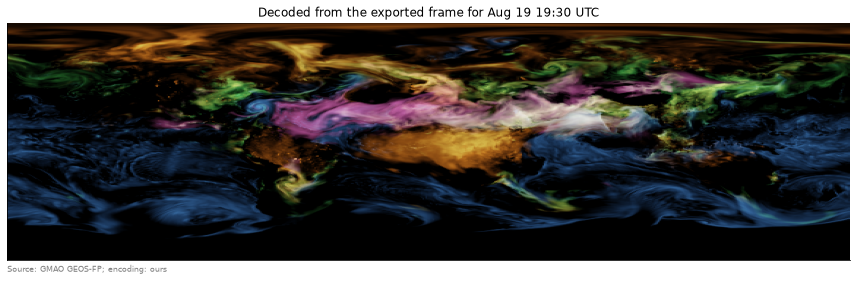

In [16]:
png = np.asarray(Image.open(TRACKS / frame_names[TIMES.get_loc(STILL)])).astype(float) / 255
decode = lambda x: ENC_AOD_LO * (ENC_AOD_HI / ENC_AOD_LO) ** x
top, bottom = png[:361][::-1], png[361:][::-1]  # back to south-up rows
back = np.stack([decode(top[..., 2]), decode(top[..., 0]), decode(bottom[..., 0]), decode(top[..., 1])])
fig, ax = plt.subplots(figsize=(12, 4))
show(ax, composite(back))
ax.set_xticks([]), ax.set_yticks([])
ax.set_title("Decoded from the exported frame for Aug 19 19:30 UTC")
source_note(ax, "Source: GMAO GEOS-FP; encoding: ours", -0.05)
plt.tight_layout()
err = np.abs(np.log10(np.clip(back, ENC_AOD_LO, ENC_AOD_HI)) - np.log10(np.clip(AOD[TIMES.get_loc(STILL)], ENC_AOD_LO, ENC_AOD_HI)))
print(f"largest round-trip error: {err.max():.4f} in log10 AOD (one 8-bit step is {np.log10(ENC_AOD_HI / ENC_AOD_LO) / 255:.4f})")

## Next steps

- Album: four tracks (Erin, Saharan Dust, Southern Africa Smoke, Spain and Etna) in `src/features/album/data/albums.js`.
- Music: one motif per event, played at its source, imitated as the plume spreads and returning at the receptor (section 9.5), with mute and solo tied to the particle toggles.
- Globe: start each track at the event's source and follow the front (`*_front_lat`, `*_front_lon`) towards the receptor.
